# CS231n Python/Numpy Review Tutorial With Google Colab

This tutorial was originally written by [Justin Johnson](https://web.eecs.umich.edu/~justincj/) for cs231n and edited by Kevin Zakka. It was adapted as a Jupyter notebook for cs228 by [Volodymyr Kuleshov](http://web.stanford.edu/~kuleshov/) and [Isaac Caswell](https://symsys.stanford.edu/viewing/symsysaffiliate/21335).

This version has been adapted for Colab by Favour Nerrise for the Spring 2026 edition of [cs231n](https://cs231n.github.io/). It runs Python3 by default.

## Introduction

Python is a great general-purpose programming language on its own, but with the help of a few popular libraries (numpy, scipy, matplotlib) it becomes a powerful environment for scientific computing.

We expect that many of you will have some experience with Python and numpy; for the rest of you, this section will serve as a quick crash course both on the Python programming language and on the use of Python for scientific computing.

If you have a MATLAB background, you may find the [NumPy for MATLAB users](https://numpy.org/doc/stable/user/numpy-for-matlab-users.html) page useful.

In this tutorial, we will cover:

* Basic Python: Basic data types (Containers, Lists, Dictionaries, Sets, Tuples), Functions, Classes
* Numpy: Arrays, Array indexing, Datatypes, Array math, Broadcasting
* Matplotlib: Plotting, Subplots, Images

## A Brief Note on Python Versions

As of Spring 2026, Google Colab uses Python 3.12 by default. For compatibility with our assignments, we will use Python 3.11.13 to enforce the Python version by clicking `Runtime -> Change Runtime Type` and selecting `2025.07` You can check your Python version at the command line by running `python --version`.


In [1]:
!python --version

Python 3.11.13


In [ ]:
# IMPORTANT - If you are running this locally or on JupyterLab instead of Colab, uncomment the following lines to install required packages.
! pip install matplotlib scikit-learn ipywidgets

## Basics of Python

Python is a high-level, dynamically typed multiparadigm programming language. Python code is often said to be almost like pseudocode, since it allows you to express very powerful ideas in very few lines of code while being very readable. As an example, here is an implementation of the classic quicksort algorithm in Python:

In [3]:
def quicksort(arr):
    if len(arr) <= 1:
        return arr
    pivot = arr[len(arr) // 2]
    left = [x for x in arr if x < pivot]
    middle = [x for x in arr if x == pivot]
    right = [x for x in arr if x > pivot]
    return quicksort(left) + middle + quicksort(right)

print(quicksort([3,6,8,10,1,2,1]))

[1, 1, 2, 3, 6, 8, 10]


### Basic data types

#### Numbers

Integers and floats work as you would expect from other languages:

In [4]:
x = 3
print(x, type(x))

3 <class 'int'>


In [5]:
print(x + 1)   # Addition
print(x - 1)   # Subtraction
print(x * 2)   # Multiplication
print(x ** 2)  # Exponentiation

4
2
6
9


In [6]:
x += 1
print(x)
x *= 2
print(x)

4
8


In [7]:
y = 2.5
print(type(y))
print(y, y + 1, y * 2, y ** 2)

<class 'float'>
2.5 3.5 5.0 6.25


Note that unlike many languages, Python does not have unary increment (x++) or decrement (x--) operators.

Python integers have arbitrary precision. Python also has a built-in type for complex numbers; you can find all of the details in the [documentation](https://docs.python.org/3/library/stdtypes.html#numeric-types-int-float-complex).

#### Booleans

Python implements all of the usual operators for Boolean logic, but uses English words rather than symbols (`&&`, `||`, etc.):

In [8]:
t, f = True, False
print(type(t))

<class 'bool'>


Now let's look at the operations:

In [9]:
print(t and f) # Logical AND;
print(t or f)  # Logical OR;
print(not t)   # Logical NOT;
print(t != f)  # Logical XOR;

False
True
False
True


#### Strings

In [10]:
hello = 'hello'   # String literals can use single quotes
world = "world"   # or double quotes; it does not matter
print(hello, len(hello))

hello 5


In [11]:
hw = hello + ' ' + world  # String concatenation
print(hw)

hello world


In [12]:
hw12 = f'{hello} {world} {12}'  # string formatting with f-string
print(hw12)

hello world 12


Python 3.6+ introduced **f-strings** (formatted string literals), which are the preferred way to format strings. You may also see the older `.format()` method in existing code:

```python
hw12 = '{} {} {}'.format(hello, world, 12)  # older style, still works
```

String objects have a bunch of useful methods; for example:

In [13]:
s = "hello"
print(s.capitalize())  # Capitalize a string
print(s.upper())       # Convert a string to uppercase; prints "HELLO"
print(s.rjust(7))      # Right-justify a string, padding with spaces
print(s.center(7))     # Center a string, padding with spaces
print(s.replace('l', '(ell)'))  # Replace all instances of one substring with another
print('  world '.strip())  # Strip leading and trailing whitespace

Hello
HELLO
  hello
 hello 
he(ell)(ell)o
world


You can find a list of all string methods in the [documentation](https://docs.python.org/3/library/stdtypes.html#string-methods).

### Containers

Python includes several built-in container types: lists, dictionaries, sets, and tuples.

#### Lists

A list is the Python equivalent of an array, but is resizeable and can contain elements of different types:

In [14]:
xs = [3, 1, 2]   # Create a list
print(xs, xs[2])
print(xs[-1])     # Negative indices count from the end of the list; prints "2"

[3, 1, 2] 2
2


In [15]:
xs[2] = 'foo'    # Lists can contain elements of different types
print(xs)

[3, 1, 'foo']


In [16]:
xs.append('bar') # Add a new element to the end of the list
print(xs)

[3, 1, 'foo', 'bar']


In [17]:
x = xs.pop()     # Remove and return the last element of the list
print(x, xs)

bar [3, 1, 'foo']


As usual, you can find all the gory details about lists in the [documentation](https://docs.python.org/3/tutorial/datastructures.html#more-on-lists).

#### Slicing

In addition to accessing list elements one at a time, Python provides concise syntax to access sublists; this is known as slicing:

In [18]:
nums = list(range(5))    # range generates a sequence of integers; list() converts it to a list
print(nums)         # Prints "[0, 1, 2, 3, 4]"
print(nums[2:4])    # Get a slice from index 2 to 4 (exclusive); prints "[2, 3]"
print(nums[2:])     # Get a slice from index 2 to the end; prints "[2, 3, 4]"
print(nums[:2])     # Get a slice from the start to index 2 (exclusive); prints "[0, 1]"
print(nums[:])      # Get a slice of the whole list; prints ["0, 1, 2, 3, 4]"
print(nums[:-1])    # Slice indices can be negative; prints ["0, 1, 2, 3]"
nums[2:4] = [8, 9] # Assign a new sublist to a slice
print(nums)         # Prints "[0, 1, 8, 9, 4]"

[0, 1, 2, 3, 4]
[2, 3]
[2, 3, 4]
[0, 1]
[0, 1, 2, 3, 4]
[0, 1, 2, 3]
[0, 1, 8, 9, 4]


#### Loops

You can loop over the elements of a list like this:

In [19]:
animals = ['cat', 'dog', 'monkey']
for animal in animals:
    print(animal)

cat
dog
monkey


If you want access to the index of each element within the body of a loop, use the built-in `enumerate` function:

In [20]:
animals = ['cat', 'dog', 'monkey']
for idx, animal in enumerate(animals):
    print(f'#{idx + 1}: {animal}')

#1: cat
#2: dog
#3: monkey


#### List comprehensions:

When programming, frequently we want to transform one type of data into another. As a simple example, consider the following code that computes square numbers:

In [21]:
nums = [0, 1, 2, 3, 4]
squares = []
for x in nums:
    squares.append(x ** 2)
print(squares)

[0, 1, 4, 9, 16]


You can make this code simpler using a list comprehension:

In [22]:
nums = [0, 1, 2, 3, 4]
squares = [x ** 2 for x in nums]
print(squares)

[0, 1, 4, 9, 16]


List comprehensions can also contain conditions:

In [23]:
nums = [0, 1, 2, 3, 4]
even_squares = [x ** 2 for x in nums if x % 2 == 0]
print(even_squares)

[0, 4, 16]


#### Dictionaries

A dictionary stores (key, value) pairs, similar to a `Map` in Java or an object in Javascript. You can use it like this:

In [24]:
d = {'cat': 'cute', 'dog': 'furry'}  # Create a new dictionary with some data
print(d['cat'])       # Get an entry from a dictionary; prints "cute"
print('cat' in d)     # Check if a dictionary has a given key; prints "True"

cute
True


In [25]:
d['fish'] = 'wet'    # Set an entry in a dictionary
print(d['fish'])      # Prints "wet"

wet


In [26]:
print(d['monkey'])  # KeyError: 'monkey' not a key of d

KeyError: 'monkey'

In [29]:
print(d.get('monkey', 'N/A'))  # Get an element with a default if it's missing; prints "N/A"
print(d.get('fish', 'N/A'))    # Get an element with a default; prints "wet"
d

N/A
wet


{'cat': 'cute', 'dog': 'furry', 'fish': 'wet'}

In [30]:
del d['fish']        # Remove an element from a dictionary
print(d.get('fish', 'N/A')) # "fish" is no longer a key; prints "N/A"

N/A


You can find all you need to know about dictionaries in the [documentation](https://docs.python.org/3/library/stdtypes.html#dict).

It is easy to iterate over the key-value pairs in a dictionary:

In [31]:
d = {'person': 2, 'cat': 4, 'spider': 8}
for animal, legs in d.items():
    print(f'A {animal} has {legs} legs')

A person has 2 legs
A cat has 4 legs
A spider has 8 legs


Dictionary comprehensions: These are similar to list comprehensions, but allow you to easily construct dictionaries. For example:

In [32]:
nums = [0, 1, 2, 3, 4]
even_num_to_square = {x: x ** 2 for x in nums if x % 2 == 0}
print(even_num_to_square)

{0: 0, 2: 4, 4: 16}


#### Sets

A set is an unordered collection of distinct elements. As a simple example, consider the following:

In [33]:
animals = {'cat', 'dog'}
print('cat' in animals)   # Check if an element is in a set; prints "True"
print('fish' in animals)  # prints "False"


True
False


In [34]:
animals.add('fish')      # Add an element to a set
print('fish' in animals)
print(len(animals))       # Number of elements in a set;

True
3


In [35]:
animals.add('cat')       # Adding an element that is already in the set does nothing
print(len(animals))
animals.remove('cat')    # Remove an element from a set
print(len(animals))

3
2


_Loops_: Iterating over a set has the same syntax as iterating over a list; however since sets are unordered, you cannot make assumptions about the order in which you visit the elements of the set:

In [37]:
animals = {'cat', 'dog', 'fish'}
for idx, animal in enumerate(animals):
    print(f'#{idx + 1}: {animal}')

#1: dog
#2: cat
#3: fish


Set comprehensions: Like lists and dictionaries, we can easily construct sets using set comprehensions:

In [38]:
from math import sqrt
print({int(sqrt(x)) for x in range(30)})

{0, 1, 2, 3, 4, 5}


#### Tuples

A tuple is an (immutable) ordered list of values. A tuple is in many ways similar to a list; one of the most important differences is that tuples can be used as keys in dictionaries and as elements of sets, while lists cannot. Here is a trivial example:

In [43]:
d = {(x, x + 1): x for x in range(10)}  # Create a dictionary with tuple keys
print(d)
t = (5, 6)       # Create a tuple
print(t)
print(type(t))
print(d[t])
print(d[(1, 2)])

{(0, 1): 0, (1, 2): 1, (2, 3): 2, (3, 4): 3, (4, 5): 4, (5, 6): 5, (6, 7): 6, (7, 8): 7, (8, 9): 8, (9, 10): 9}
(5, 6)
<class 'tuple'>
5
1


In [41]:
t[0] = 1  # Raises a TypeError — tuples are immutable

TypeError: 'tuple' object does not support item assignment

### Functions

Python functions are defined using the `def` keyword. For example:

In [44]:
def sign(x):
    if x > 0:
        return 'positive'
    elif x < 0:
        return 'negative'
    else:
        return 'zero'

for x in [-1, 0, 1]:
    print(sign(x))

negative
zero
positive


We will often define functions to take optional keyword arguments, like this:

In [45]:
def hello(name, loud=False):
    if loud:
        print(f'HELLO, {name.upper()}')
    else:
        print(f'Hello, {name}!')

hello('Bob')
hello('Fred', loud=True)

Hello, Bob!
HELLO, FRED


### Classes

The syntax for defining classes in Python is straightforward:

In [46]:
class Greeter:

    # Constructor
    def __init__(self, name):
        self.name = name  # Create an instance variable

    # Instance method
    def greet(self, loud=False):
        if loud:
          print(f'HELLO, {self.name.upper()}')
        else:
          print(f'Hello, {self.name}!')

g = Greeter('Fred')  # Construct an instance of the Greeter class
g.greet()            # Call an instance method; prints "Hello, Fred"
g.greet(loud=True)   # Call an instance method; prints "HELLO, FRED!"

Hello, Fred!
HELLO, FRED


## Numpy

Numpy is the core library for scientific computing in Python. It provides a high-performance multidimensional array object, and tools for working with these arrays. If you are already familiar with MATLAB, you might find the [NumPy for MATLAB users](https://numpy.org/doc/stable/user/numpy-for-matlab-users.html) page useful to get started with Numpy.

To use Numpy, we first need to import the `numpy` package:

In [47]:
import numpy as np

### Arrays

A numpy array is a grid of values, all of the same type, and is indexed by a tuple of nonnegative integers. The number of dimensions is the `ndim` of the array; the `shape` of an array is a tuple of integers giving the size of the array along each dimension.

We can initialize numpy arrays from nested Python lists, and access elements using square brackets:

In [48]:
a = np.array([1, 2, 3])  # Create a 1D array
print(type(a), a.shape, a[0], a[1], a[2])
a[0] = 5                 # Change an element of the array
print(a)

<class 'numpy.ndarray'> (3,) 1 2 3
[5 2 3]


In [49]:
b = np.array([[1,2,3],[4,5,6]])   # Create a 2D array
print(b)

[[1 2 3]
 [4 5 6]]


In [50]:
print(b.shape)
print(b.ndim)
print(b[0, 0], b[0, 1], b[1, 0])

(2, 3)
2
1 2 4


Numpy also provides many functions to create arrays:

In [51]:
a = np.zeros((2,2))  # Create an array of all zeros
print(a)

[[0. 0.]
 [0. 0.]]


In [52]:
b = np.ones((1,2))   # Create an array of all ones
print(b)

[[1. 1.]]


In [53]:
c = np.full((2,2), 7) # Create a constant array
print(c)

[[7 7]
 [7 7]]


In [54]:
d = np.eye(2)        # Create a 2x2 identity matrix
print(d)

[[1. 0.]
 [0. 1.]]


In [55]:
rng = np.random.default_rng() # Create a random number generator
e = rng.random((2,2))         # Create an array filled with random values
print(e)

[[0.53630264 0.77037894]
 [0.95200367 0.13368099]]


In this course you will frequently work with arrays that have more than two dimensions —
for example, a color image has shape `(height, width, channels)` and a batch of images has shape `(num_images, height, width, channels)`.
The `axis` parameter in NumPy functions specifies which dimension to operate along:

In [59]:
# A 3D array: shape (2, 3, 4)
a = np.ones((2, 3, 4))
print(a)
print(f'Shape: {a.shape}')
print(f'Sum over axis 0: {np.sum(a, axis=0).shape}')  # (3, 4)
print(f'Sum over axis 2: {np.sum(a, axis=2).shape}')  # (2, 3)
print(f'Sum over axis 1: {np.sum(a, axis=1).shape}')  # (2, 4)
print(f'Sum over axes (0,2): {np.sum(a, axis=(0, 2)).shape}')  # (3,)

[[[1. 1. 1. 1.]
  [1. 1. 1. 1.]
  [1. 1. 1. 1.]]

 [[1. 1. 1. 1.]
  [1. 1. 1. 1.]
  [1. 1. 1. 1.]]]
Shape: (2, 3, 4)
Sum over axis 0: (3, 4)
Sum over axis 2: (2, 3)
Sum over axis 1: (2, 4)
Sum over axes (0,2): (3,)


### Array indexing

Numpy offers several ways to index into arrays.

Slicing: Similar to Python lists, numpy arrays can be sliced. Since arrays may be multidimensional, you must specify a slice for each dimension of the array:

In [60]:
# Create the following 2D array with shape (3, 4)
# [[ 1  2  3  4]
#  [ 5  6  7  8]
#  [ 9 10 11 12]]
a = np.array([[1,2,3,4], [5,6,7,8], [9,10,11,12]])

# Use slicing to pull out the subarray consisting of the first 2 rows
# and columns 1 and 2; b is the following array of shape (2, 2):
# [[2 3]
#  [6 7]]
b = a[:2, 1:3]
print(b)

[[2 3]
 [6 7]]


A slice of an array is a **view** into the same data, so modifying it will modify the original array. This is a common source of bugs — if you need an independent copy, use `.copy()`.

In [62]:
print(a[0, 1])
b[0, 0] = 77    # b[0, 0] is the same piece of data as a[0, 1]
print(a[0, 1])

77
77


You can also mix integer indexing with slice indexing. However, doing so will yield an array of lower dimensionality than the original array. Note that this is quite different from the way that MATLAB handles array slicing:

In [63]:
# Create the following 2D array with shape (3, 4)
a = np.array([[1,2,3,4], [5,6,7,8], [9,10,11,12]])
print(a)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]


Two ways of accessing the data in the middle row of the array.
Mixing integer indexing with slices yields an array of fewer dimensions,
while using only slices yields an array of the same dimensionality as the
original array:

In [64]:
row_r1 = a[1, :]    # 1D view of the second row of a
row_r2 = a[1:2, :]  # 2D view of the second row of a
row_r3 = a[[1], :]  # 2D view of the second row of a
print(row_r1, row_r1.shape)
print(row_r2, row_r2.shape)
print(row_r3, row_r3.shape)

[5 6 7 8] (4,)
[[5 6 7 8]] (1, 4)
[[5 6 7 8]] (1, 4)


In [65]:
# We can make the same distinction when accessing columns of an array:
col_r1 = a[:, 1]
col_r2 = a[:, 1:2]
print(col_r1, col_r1.shape)
print()
print(col_r2, col_r2.shape)

[ 2  6 10] (3,)

[[ 2]
 [ 6]
 [10]] (3, 1)


Integer array indexing: When you index into numpy arrays using slicing, the resulting array view will always be a subarray of the original array. In contrast, integer array indexing allows you to construct arbitrary arrays using the data from another array. Here is an example:

In [66]:
a = np.array([[1,2], [3, 4], [5, 6]])

# An example of integer array indexing.
# The returned array will have shape (3,) and
print(a[[0, 1, 2], [0, 1, 0]])

# The above example of integer array indexing is equivalent to this:
print(np.array([a[0, 0], a[1, 1], a[2, 0]]))

[1 4 5]
[1 4 5]


In [67]:
# When using integer array indexing, you can reuse the same
# element from the source array:
print(a[[0, 0], [1, 1]])

# Equivalent to the previous integer array indexing example
print(np.array([a[0, 1], a[0, 1]]))

[2 2]
[2 2]


One useful trick with integer array indexing is selecting or mutating one element from each row of a matrix:

In [68]:
# Create a new array from which we will select elements
a = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])
print(a)

[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]


In [69]:
# Create an array of indices
b = np.array([0, 2, 0, 1])

# Select one element from each row of a using the indices in b
print(a[np.arange(4), b])  # Prints "[ 1  6  7 11]"

[ 1  6  7 11]


In [70]:
# Mutate one element from each row of a using the indices in b
a[np.arange(4), b] += 10
print(a)

[[11  2  3]
 [ 4  5 16]
 [17  8  9]
 [10 21 12]]


Boolean array indexing: Boolean array indexing lets you pick out arbitrary elements of an array. Frequently this type of indexing is used to select the elements of an array that satisfy some condition. Here is an example:

In [71]:
a = np.array([[1,2], [3, 4], [5, 6]])
print(a)

bool_idx = (a > 2)  # Find the elements of a that are bigger than 2;
                    # this returns a numpy array of Booleans of the same
                    # shape as a, where each slot of bool_idx tells
                    # whether that element of a is > 2.

print(bool_idx)

[[1 2]
 [3 4]
 [5 6]]
[[False False]
 [ True  True]
 [ True  True]]


In [72]:
# We use boolean array indexing to construct a 1D array
# consisting of the elements of a corresponding to the True values
# of bool_idx
print(a[bool_idx])

# We can do all of the above in a single concise statement:
print(a[a > 2])

[3 4 5 6]
[3 4 5 6]


For brevity we have left out a lot of details about numpy array indexing; if you want to know more you should read the [documentation](https://numpy.org/doc/stable/user/basics.indexing.html).

### Datatypes

Every numpy array is a grid of elements of the same type. Numpy provides a large set of numeric datatypes that you can use to construct arrays. Numpy tries to guess a datatype when you create an array, but functions that construct arrays usually also include an optional argument to explicitly specify the datatype. Here is an example:

In [73]:
x = np.array([1, 2])  # Let numpy choose the datatype
y = np.array([1.0, 2.0])  # Let numpy choose the datatype
z = np.array([1, 2], dtype=np.int64)  # Force a particular datatype

print(x.dtype, y.dtype, z.dtype)

int64 float64 int64


You can read all about numpy datatypes in the [documentation](https://numpy.org/doc/stable/reference/arrays.dtypes.html).

### Array math

Basic mathematical functions operate elementwise on arrays, and are available both as operator overloads and as functions in the numpy module:

In [74]:
x = np.array([[1,2],[3,4]], dtype=np.float64)
y = np.array([[5,6],[7,8]], dtype=np.float64)

# Elementwise sum; both produce the array
print(x + y)
print(np.add(x, y))

[[ 6.  8.]
 [10. 12.]]
[[ 6.  8.]
 [10. 12.]]


In [75]:
# Elementwise difference; both produce the array
print(x - y)
print(np.subtract(x, y))

[[-4. -4.]
 [-4. -4.]]
[[-4. -4.]
 [-4. -4.]]


In [76]:
# Elementwise product; both produce the array
print(x * y)
print(np.multiply(x, y))

[[ 5. 12.]
 [21. 32.]]
[[ 5. 12.]
 [21. 32.]]


In [78]:
# Elementwise division; both produce the array
# [[ 0.2         0.33333333]
#  [ 0.42857143  0.5       ]]
print(x / y)
print(np.divide(x, y))

[[0.2        0.33333333]
 [0.42857143 0.5       ]]
[[0.2        0.33333333]
 [0.42857143 0.5       ]]


In [79]:
# Elementwise square root; produces the array
# [[ 1.          1.41421356]
#  [ 1.73205081  2.        ]]
print(np.sqrt(x))

[[1.         1.41421356]
 [1.73205081 2.        ]]


Note that unlike MATLAB, `*` is elementwise multiplication, not matrix multiplication. We instead use the `@` operator to compute inner products of vectors, to multiply a vector by a matrix, and to multiply matrices:

In [80]:
x = np.array([[1,2],[3,4]])
y = np.array([[5,6],[7,8]])

v = np.array([9,10])
w = np.array([11, 12])

# Inner product of vectors; produces 219
print(v @ w)

219


The `@` operator is the standard way to do matrix multiplication in Python. You may also see `np.dot()` and `v.dot(w)` in older code, which are equivalent for these operations:

In [81]:
# These are equivalent to v @ w
print(v.dot(w))
print(np.dot(v, w))

219
219


In [82]:
# Matrix / vector product; both produce the 1D array [29 67]
print(x @ v)
print(np.dot(x, v))

[29 67]
[29 67]


In [83]:
# Matrix / matrix product; both produce the 2D array
# [[19 22]
#  [43 50]]
print(x @ y)
print(np.dot(x, y))

[[19 22]
 [43 50]]
[[19 22]
 [43 50]]


Numpy provides many useful functions for performing computations on arrays; one of the most useful is `sum`:

In [84]:
x = np.array([[1,2],[3,4]])

print(np.sum(x))  # Compute sum of all elements; prints "10"
print(np.sum(x, axis=0))  # Compute sum of each column; prints "[4 6]"
print(np.sum(x, axis=1))  # Compute sum of each row; prints "[3 7]"

10
[4 6]
[3 7]


Several other NumPy functions come up frequently in deep learning:

In [85]:
x = np.array([[1, -2, 3], [-4, 5, -6]])

print(np.max(x, axis=1))       # Max along each row: [3 5]
print(np.argmax(x, axis=1))    # Index of max in each row: [2 1]
print(np.clip(x, -3, 3))       # Restrict/Clip(limit) values to [-3, 3]
print(np.where(x > 0, x, 0))   # ReLU: keep positives, zero out negatives

# exp and log (used in softmax, cross-entropy loss)
scores = np.array([2.0, 1.0, 0.1])
exp_scores = np.exp(scores)
print(f'softmax: {exp_scores / np.sum(exp_scores)}')

# L2 norm (used in gradient checking, regularization)
print(f'L2 norm: {np.linalg.norm(scores)}')

[3 5]
[2 1]
[[ 1 -2  3]
 [-3  3 -3]]
[[1 0 3]
 [0 5 0]]
softmax: [0.65900114 0.24243297 0.09856589]
L2 norm: 2.238302928559939


You can find the full list of mathematical functions provided by numpy in the [documentation](https://numpy.org/doc/stable/reference/routines.math.html).

Apart from computing mathematical functions using arrays, we frequently need to reshape or otherwise manipulate data in arrays. The simplest example of this type of operation is transposing a matrix; to transpose a matrix, simply use the T attribute of an array object:

In [86]:
x = np.array([[1,2],[3,4]])
print(x)
print("transpose\n", x.T)

[[1 2]
 [3 4]]
transpose
 [[1 3]
 [2 4]]


In [87]:
v = np.array([[1,2,3]])
print(v)
print("transpose\n", v.T)

[[1 2 3]]
transpose
 [[1]
 [2]
 [3]]


Another very common operation is `reshape`, which changes the shape of an array without changing its data.
You will use this constantly — for example, flattening an image into a vector, or reshaping weight matrices:

In [88]:
x = np.array([[1, 2, 3], [4, 5, 6]])
print(f'Original shape: {x.shape}')  # (2, 3)

# Flatten to a 1D vector
print(x.reshape(-1))     # -1 means 'infer this dimension'
print(x.flatten())       # equivalent, always returns a copy

# Reshape to a column vector
print(x.reshape(6, 1))

# Reshape to a different 2D shape
print(x.reshape(3, 2))

Original shape: (2, 3)
[1 2 3 4 5 6]
[1 2 3 4 5 6]
[[1]
 [2]
 [3]
 [4]
 [5]
 [6]]
[[1 2]
 [3 4]
 [5 6]]


### Broadcasting

Broadcasting is a powerful mechanism that allows numpy to work with arrays of different shapes when performing arithmetic operations. Frequently we have a smaller array and a larger array, and we want to use the smaller array multiple times to perform some operation on the larger array.

For example, suppose that we want to add a constant vector to each row of a matrix. We could do it like this:

In [89]:
# We will add the vector v to each row of the matrix x,
# storing the result in the matrix y
x = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])
v = np.array([1, 0, 1])
y = np.empty_like(x)   # Create an empty matrix with the same shape as x

# Add the vector v to each row of the matrix x with an explicit loop
for i in range(4):
    y[i, :] = x[i, :] + v

print(y)

[[ 2  2  4]
 [ 5  5  7]
 [ 8  8 10]
 [11 11 13]]


This works; however when the matrix `x` is very large, computing an explicit loop in Python could be slow. Note that adding the vector v to each row of the matrix `x` is equivalent to forming a matrix `vv` by stacking multiple copies of `v` vertically, then performing elementwise summation of `x` and `vv`. We could implement this approach like this:

In [90]:
vv = np.tile(v, (4, 1))  # Stack 4 copies of v on top of each other
print(vv)                # Prints "[[1 0 1]
                         #          [1 0 1]
                         #          [1 0 1]
                         #          [1 0 1]]"

[[1 0 1]
 [1 0 1]
 [1 0 1]
 [1 0 1]]


In [91]:
y = x + vv  # Add x and vv elementwise
print(y)

[[ 2  2  4]
 [ 5  5  7]
 [ 8  8 10]
 [11 11 13]]


Numpy broadcasting allows us to perform this computation without actually creating multiple copies of v. Consider this version, using broadcasting:

In [93]:
# We will add the vector v to each row of the matrix x,
# storing the result in the matrix y
x = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])
v = np.array([1, 0, 1])
y = x + v  # Add v to each row of x using broadcasting
print(y)

[[ 2  2  4]
 [ 5  5  7]
 [ 8  8 10]
 [11 11 13]]


The line `y = x + v` works even though `x` has shape `(4, 3)` and `v` has shape `(3,)` due to broadcasting; this line works as if v actually had shape `(4, 3)`, where each row was a copy of `v`, and the sum was performed elementwise.

Broadcasting two arrays together follows these rules:

1. If the arrays do not have the same number of dimensions, prepend the shape of the lower-dimensional array with 1s until both shapes have the same length.
2. The two arrays are said to be compatible in a dimension if they have the same size in the dimension, or if one of the arrays has size 1 in that dimension.
3. The arrays can be broadcast together if they are compatible in all dimensions.
4. After broadcasting, each array behaves as if it had shape equal to the elementwise maximum of shapes of the two input arrays.
5. In any dimension where one array had size 1 and the other array had size greater than 1, the first array behaves as if it were copied along that dimension.

If this explanation does not make sense, try reading the [broadcasting documentation](https://numpy.org/doc/stable/user/basics.broadcasting.html).

Functions that support broadcasting are known as universal functions. You can find the list of all universal functions in the [documentation](https://numpy.org/doc/stable/reference/ufuncs.html#available-ufuncs).

Here are some applications of broadcasting:

Use the widget below to experiment with broadcasting. Change the array shapes and see whether they are compatible:

In [94]:
from ipywidgets import interact_manual, IntSlider, Layout

def explore_broadcasting(a_rows=4, a_cols=3, b_rows=1, b_cols=3):
    shape_a = (a_rows, a_cols)
    shape_b = (b_rows, b_cols)

    try:
        a = np.ones(shape_a)
        b = np.ones(shape_b)
        result = a + b
        print(f'  A shape: {shape_a}')
        print(f'  B shape: {shape_b}')
        print(f'  Result:  {result.shape}  ✓ broadcast succeeded')

        # Show the rule that applied
        for dim in range(2):
            sa, sb = shape_a[dim], shape_b[dim]
            if sa == sb:
                print(f'  Dim {dim}: {sa} == {sb} (same size)')
            elif sa == 1:
                print(f'  Dim {dim}: {sa} → {sb} (A stretched)')
            elif sb == 1:
                print(f'  Dim {dim}: {sb} → {sa} (B stretched)')
    except ValueError as e:
        print(f'  A shape: {shape_a}')
        print(f'  B shape: {shape_b}')
        print(f'  ✗ {e}')

style = Layout(width="200px")
interact_manual(explore_broadcasting,
         a_rows=IntSlider(min=1, max=5, value=4, description="A rows", layout=style),
         a_cols=IntSlider(min=1, max=5, value=3, description="A cols", layout=style),
         b_rows=IntSlider(min=1, max=5, value=1, description="B rows", layout=style),
         b_cols=IntSlider(min=1, max=5, value=3, description="B cols", layout=style));

interactive(children=(IntSlider(value=4, description='A rows', layout=Layout(width='200px'), max=5, min=1), In…

In [95]:
# Compute outer product of vectors
v = np.array([1,2,3])  # v has shape (3,)
w = np.array([4,5])    # w has shape (2,)
# To compute an outer product, we first reshape v to be a column
# vector of shape (3, 1); we can then broadcast it against w to yield
# an output of shape (3, 2), which is the outer product of v and w:

print(np.reshape(v, (3, 1)) * w)

[[ 4  5]
 [ 8 10]
 [12 15]]


In [96]:
# Add a vector to each row of a matrix
x = np.array([[1,2,3], [4,5,6]])
# x has shape (2, 3) and v has shape (3,) so they broadcast to (2, 3),
# giving the following matrix:

print(x + v)

[[2 4 6]
 [5 7 9]]


In [97]:
# Add a vector to each column of a matrix
# x has shape (2, 3) and w has shape (2,).
# If we transpose x then it has shape (3, 2) and can be broadcast
# against w to yield a result of shape (3, 2); transposing this result
# yields the final result of shape (2, 3) which is the matrix x with
# the vector w added to each column. Gives the following matrix:

print((x.T + w).T)

[[ 5  6  7]
 [ 9 10 11]]


In [98]:
# Another solution is to reshape w to be a row vector of shape (2, 1);
# we can then broadcast it directly against x to produce the same
# output.
print(x + np.reshape(w, (2, 1)))

[[ 5  6  7]
 [ 9 10 11]]


In [99]:
# Multiply a matrix by a constant:
# x has shape (2, 3). Numpy treats scalars as arrays of shape ();
# these can be broadcast together to shape (2, 3), producing the
# following array:
print(x * 2)

[[ 2  4  6]
 [ 8 10 12]]


Broadcasting typically makes your code more concise and faster, so you should strive to use it where possible.

### Vectorization

A key skill for this course is **replacing Python loops with vectorized NumPy operations**.
NumPy operations run in optimized C under the hood, so they can be orders of magnitude faster than equivalent Python loops.
Whenever you find yourself writing a `for` loop over array elements, ask whether you can express it with array operations instead.

In [100]:
from ipywidgets import interact_manual, IntSlider
import time

def benchmark_vectorization(size=500):
    x = np.random.default_rng(0).standard_normal((size, size))

    # Python loop
    start = time.time()
    result_loop = np.zeros_like(x)
    for i in range(x.shape[0]):
        for j in range(x.shape[1]):
            result_loop[i, j] = max(0, x[i, j])
    loop_time = time.time() - start

    # Vectorized
    start = time.time()
    result_vec = np.maximum(0, x)
    vec_time = time.time() - start

    speedup = loop_time / vec_time if vec_time > 0 else float("inf")
    print(f'Array size: {size}x{size} ({size*size:,} elements)')
    print(f'Python loop: {loop_time:.4f}s')
    print(f'Vectorized:  {vec_time:.6f}s')
    print(f'Speedup:     {speedup:.0f}x faster')

    # Visual bar comparison
    bar_len = 40
    print(f'\nLoop       {"█" * bar_len}')
    vec_bar = max(1, int(bar_len * vec_time / loop_time))
    print(f'Vectorized {"█" * vec_bar}')

interact_manual(benchmark_vectorization,
         size=IntSlider(min=100, max=2000, step=100, value=500,
                        description='Array size'));

interactive(children=(IntSlider(value=500, description='Array size', max=2000, min=100, step=100), Button(desc…

### Images as NumPy Arrays

In computer vision, images are just NumPy arrays. A color image is a 3D array of shape `(H, W, 3)` (height, width, RGB channels),
and a batch of images is a 4D array of shape `(N, H, W, 3)`. Understanding shapes and axes is essential for the assignments.

In [102]:
# Simulate a batch of 16 RGB images, each 32x32 pixels
images = np.random.default_rng(42).integers(0, 256, size=(16, 32, 32, 3), dtype=np.uint8)
print(f'Batch shape: {images.shape}')    # (N, H, W, C)
print(f'Single image: {images[0].shape}') # (H, W, C)
print(f'Red channel:  {images[0, :, :, 0].shape}')  # (H, W)

# Compute mean pixel value per channel across the whole batch
channel_means = images.mean(axis=(0, 1, 2))  # average over N, H, W
print(f'Mean RGB: {channel_means}')

Batch shape: (16, 32, 32, 3)
Single image: (32, 32, 3)
Red channel:  (32, 32)
Mean RGB: [126.78192139 125.8036499  127.44012451]


This brief overview has touched on many of the important things that you need to know about numpy, but is far from complete. Check out the [numpy reference](https://numpy.org/doc/stable/reference/) to find out much more about numpy.

## Matplotlib

Matplotlib is a plotting library. In this section we give a brief introduction to the `matplotlib.pyplot` module, which provides a plotting system similar to that of MATLAB.

In [103]:
import matplotlib.pyplot as plt

In modern versions of Colab and Jupyter, matplotlib plots are displayed inline by default, so no special setup is needed.

### Plotting

The most important function in `matplotlib` is plot, which allows you to plot 2D data. Here is a simple example:

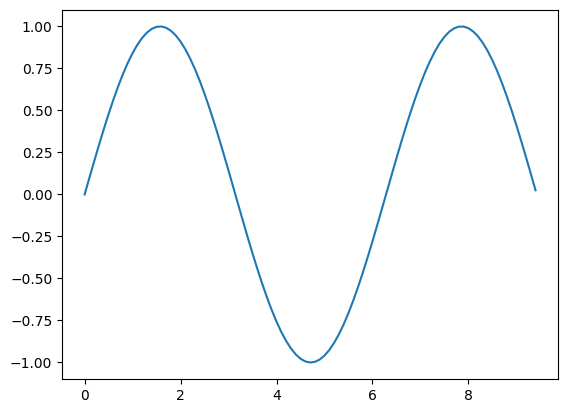

In [104]:
# Compute the x and y coordinates for points on a sine curve
x = np.arange(0, 3 * np.pi, 0.1)
y = np.sin(x)

# Plot the points using matplotlib
plt.plot(x, y)

With just a little bit of extra work we can easily plot multiple lines at once, and add a title, legend, and axis labels:

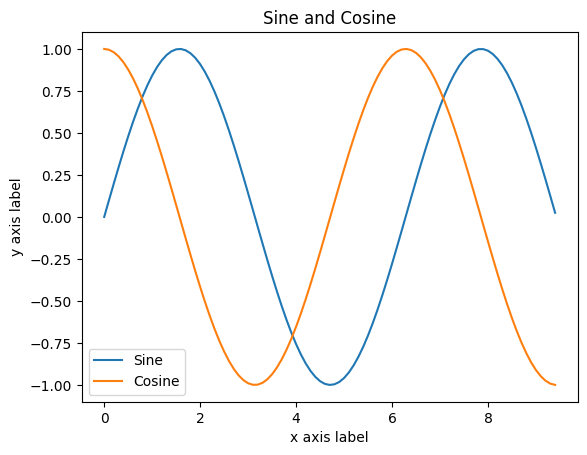

In [105]:
y_sin = np.sin(x)
y_cos = np.cos(x)

# Plot the points using matplotlib
plt.plot(x, y_sin)
plt.plot(x, y_cos)
plt.xlabel('x axis label')
plt.ylabel('y axis label')
plt.title('Sine and Cosine')
plt.legend(['Sine', 'Cosine'])

### Subplots

You can plot different things in the same figure using the subplot function. Here is an example:

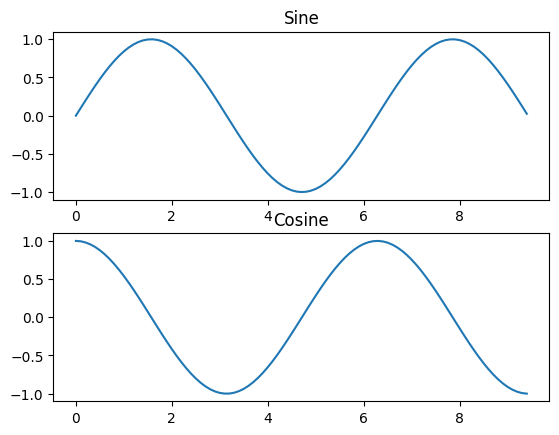

In [106]:
# Compute the x and y coordinates for points on sine and cosine curves
x = np.arange(0, 3 * np.pi, 0.1)
y_sin = np.sin(x)
y_cos = np.cos(x)

# Set up a subplot grid that has height 2 and width 1,
# and set the first such subplot as active.
plt.subplot(2, 1, 1)

# Make the first plot
plt.plot(x, y_sin)
plt.title('Sine')

# Set the second subplot as active, and make the second plot.
plt.subplot(2, 1, 2)
plt.plot(x, y_cos)
plt.title('Cosine')

# Show the figure.
plt.show()

You can read much more about the `subplot` function in the [documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplot.html).

### Images

In a computer vision course, you will constantly use `matplotlib` to display and inspect images.
The `imshow` function displays a NumPy array as an image.

Image shape: (427, 640, 3)
Dtype: uint8


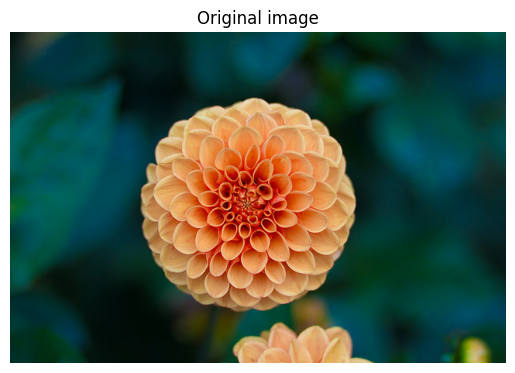

In [108]:
from sklearn.datasets import load_sample_image

# sklearn ships with a sample image: "flower.jpg"
img_array = load_sample_image('flower.jpg')

print(f'Image shape: {img_array.shape}')  # (H, W, 3)
print(f'Dtype: {img_array.dtype}')         # uint8, values 0-255

plt.imshow(img_array)
plt.title('Original image')
plt.axis('off')
plt.show()

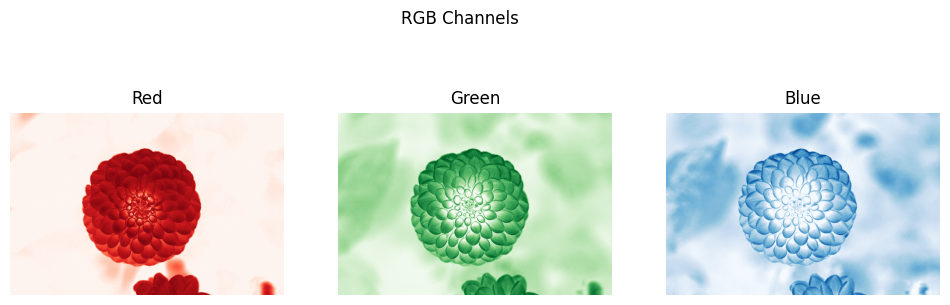

In [109]:
# Visualize individual color channels
channel_names = ['Red', 'Green', 'Blue']
cmaps = ['Reds', 'Greens', 'Blues']

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i in range(3):
    axes[i].imshow(img_array[:, :, i], cmap=cmaps[i])
    axes[i].set_title(channel_names[i])
    axes[i].axis('off')
plt.suptitle('RGB Channels')
plt.show()

Since images are just NumPy arrays, you can manipulate them with all the array operations you already know.
Try adjusting the sliders below to crop, flip, and tint the image interactively:

interactive(children=(IntSlider(value=0, description='y start', max=426), IntSlider(value=427, description='y …

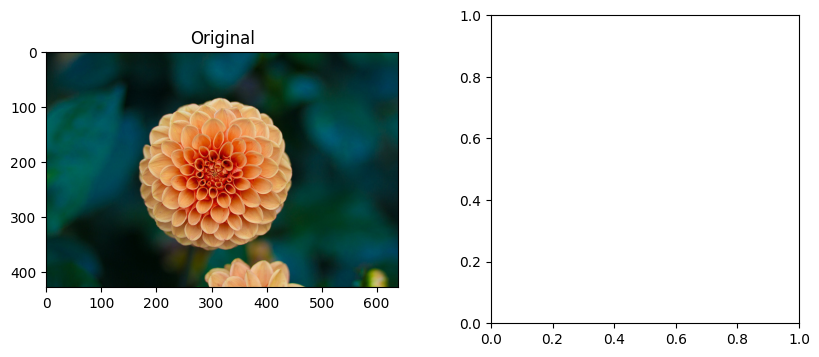

In [110]:
from ipywidgets import interact_manual, IntSlider, FloatSlider, Checkbox

H, W = img_array.shape[:2]

def manipulate_image(y_start=0, y_end=H, x_start=0, x_end=W,
                     h_flip=False, v_flip=False,
                     red=1.0, green=1.0, blue=1.0):
    # Crop
    img = img_array[y_start:y_end, x_start:x_end]
    # Flip
    if h_flip:
        img = img[:, ::-1, :]
    if v_flip:
        img = img[::-1, :, :]
    # Tint via broadcasting
    tint = img * np.array([red, green, blue])
    tint = np.clip(tint, 0, 255).astype(np.uint8)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(img_array)
    axes[0].set_title('Original')
    axes[1].imshow(tint)
    axes[1].set_title(f'Modified [{y_start}:{y_end}, {x_start}:{x_end}]')
    for ax in axes: ax.axis('off')
    plt.tight_layout()
    plt.show()

interact_manual(manipulate_image,
         y_start=IntSlider(min=0, max=H-1, value=0, description="y start"),
         y_end=IntSlider(min=1, max=H, value=H, description="y end"),
         x_start=IntSlider(min=0, max=W-1, value=0, description="x start"),
         x_end=IntSlider(min=1, max=W, value=W, description="x end"),
         h_flip=Checkbox(value=False, description="Horizontal flip"),
         v_flip=Checkbox(value=False, description="Vertical flip"),
         red=FloatSlider(min=0, max=1.5, step=0.1, value=1.0, description="Red"),
         green=FloatSlider(min=0, max=1.5, step=0.1, value=1.0, description="Green"),
         blue=FloatSlider(min=0, max=1.5, step=0.1, value=1.0, description="Blue"));

## Conclusion

This has been a brief overview of Python, NumPy, and Matplotlib, which are the core tools you will use throughout CS231N.
The key takeaways to keep in mind as you start the assignments:

- **Vectorize your code.** Avoid Python loops over array elements; use NumPy operations instead. This will be the difference between code that runs in seconds vs. minutes.
- **Understand array shapes.** Most debugging in this course comes down to shape mismatches. Use `.shape` liberally and think in terms of `(N, H, W, C)` for image batches.
- **Use broadcasting.** Once it clicks, broadcasting lets you write concise, fast code without manually tiling or reshaping arrays.

You don't need to memorize every function so knowing how to look things up is just as important.

### Additional Resources

**Python**
- [Official Python Tutorial](https://docs.python.org/3/tutorial/) — comprehensive walkthrough of the language
- [Real Python](https://realpython.com/) — practical tutorials and guides

**NumPy**
- [NumPy Quickstart](https://numpy.org/doc/stable/user/quickstart.html) — official getting-started guide
- [NumPy for MATLAB Users](https://numpy.org/doc/stable/user/numpy-for-matlab-users.html) — side-by-side comparison
- [100 NumPy Exercises](https://github.com/rougier/numpy-100) — practice problems from beginner to advanced

**Matplotlib**
- [Pyplot Tutorial](https://matplotlib.org/stable/tutorials/pyplot.html) — official intro
- [Matplotlib Cheatsheets](https://matplotlib.org/cheatsheets/) — handy quick-reference PDFs

**CS231N-Specific**
- [CS231N Course Website](https://cs231n.github.io/) — lecture notes, assignments, and syllabus
- [NumPy/SciPy Cheat Sheet for CS231N](https://cs231n.github.io/python-numpy-tutorial/) — the original version of this tutorial on the course website